# Train the Cascade Predictor (clean, textbook version)

Predicts, for every edge in the causal airshed graph, the probability that the
**target city** crosses the severe PM2.5 threshold (120 µg/m³) within the edge's
transport delay after a **source city** spike.

**Design principles**

1. **One model, one notebook.** No Optuna sweeps, no SHAP, no ablation suite —
   a plain, well-calibrated gradient-boosted classifier with honest metrics.
2. **Train/serve parity.** The feature list is *exactly* the set the production
   pipeline (`scripts/airshed_pipeline.py → _predict_cascade`) can compute from
   live data. The previous artifact trained on 33 features of which ~10 were
   always missing at inference (silently imputed) — that skew is fixed here.
3. **Chronological splits.** Train → validation → test follow calendar time, so
   the test set is genuinely "the future" and calibration never peeks at it.
4. **Contract compatibility.** The saved artifact exposes the same keys the
   pipeline already loads: `classifier`, `imputer`, `feature_cols`,
   `optimal_decision_threshold` (plus provenance metadata).

## 1. Setup

In [1]:
import json
import math
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    RocCurveDisplay, PrecisionRecallDisplay,
    average_precision_score, brier_score_loss, confusion_matrix,
    f1_score, fbeta_score, recall_score, roc_auc_score,
)
import matplotlib
import matplotlib.pyplot as plt

matplotlib.rcParams["figure.dpi"] = 110

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = PROJECT_ROOT / "data"
MODELS = DATA / "models"

PARQUET_PATH   = DATA / "processed" / "master_multi_city_4h.parquet"
CLIMATOLOGY    = MODELS / "pm25_climatology.json"
CAUSAL_GRAPH   = MODELS / "causal_graph.json"
CITIES_META    = DATA / "raw" / "cities_metadata.json"
ARTIFACT_PATH  = MODELS / "cascade_predictor.pkl"
METRICS_PATH   = PROJECT_ROOT / "notebooks" / "metrics.json"

STEP_HOURS   = 4          # data grid resolution
SEVERE_UGM3  = 120.0      # target "severe" threshold (matches pipeline PM25_SEVERE_THRESHOLD)
SOURCE_Z     = 1.5        # source spike definition (informational)
LABEL_TOL    = 1          # label window tolerance, in 4h steps

SPLIT_TRAIN_END = "2024-06-30 23:59:59"
SPLIT_VAL_END   = "2025-01-31 23:59:59"

RANDOM_STATE = 42
print("setup ok")

setup ok


## 2. Load data

The parquet is a complete 4-hourly grid: 20 cities × 6 slots/day over ~3 years.
The climatology artifact provides the per-city / per-month / per-hour PM2.5
baseline that the production pipeline also uses for anomaly z-scores.

In [2]:
df = pd.read_parquet(PARQUET_PATH)
df["time_4h"] = pd.to_datetime(df["time_4h"])

with open(CLIMATOLOGY) as f:
    clim = json.load(f)
with open(CAUSAL_GRAPH) as f:
    graph = json.load(f)
with open(CITIES_META) as f:
    cities_meta = json.load(f)

city_coords = {c["id"]: (c["lat"], c["lon"]) for c in cities_meta}
edges = graph["edges"]
print(f"rows={len(df):,}  cities={df['city_id'].nunique()}  edges={len(edges)}")
print(f"time range: {df['time_4h'].min()} to {df['time_4h'].max()}")

rows=131,520  cities=20  edges=50
time range: 2023-01-01 00:00:00 to 2025-12-31 20:00:00


## 3. Per-city series with climatological z-scores

Z-score formula is identical to production (`airshed_pipeline.compute_anomaly_zscore`):
`z = (pm2.5 − seasonal_mean) / seasonal_std` using the `(city, month, hour)` key.

In [3]:
FEATURE_COLS = [
    "source_pm25_t", "source_pm25_zscore_t", "source_wind_speed_t",
    "source_wind_u_t", "source_wind_v_t", "source_humidity_t", "source_temp_t",
    "target_pm25_t", "target_pm25_zscore_t", "target_wind_speed_t",
    "target_humidity_t", "target_temp_t",
    "correlation_strength", "delay_hours", "bearing_deg",
    "pressure_gradient_t", "temp_gradient_t", "distance_km",
    "implied_speed_kmh", "wind_transport_alignment",
    "hour_sin", "hour_cos", "month_sin", "month_cos",
]
print(f"{len(FEATURE_COLS)} features — every one computable at inference time")

24 features — every one computable at inference time


In [4]:
# Flatten the climatology JSON into a lookup table
clim_rows = []
for cid, months in clim["seasonal"].items():
    for key, stats in months.items():
        month, hour = key.split("_")
        clim_rows.append((cid, int(month), int(hour), stats["mean"], stats["std"]))
clim_df = pd.DataFrame(clim_rows, columns=["city_id", "month", "hour", "clim_mean", "clim_std"])

city_frames = {}
for cid, grp in df.groupby("city_id"):
    g = grp.set_index("time_4h").sort_index()
    tmp = pd.DataFrame({
        "time_4h": g.index,
        "month": g.index.month,
        "hour": g.index.hour,
    }).assign(city_id=cid).merge(clim_df, on=["city_id", "month", "hour"], how="left")
    g = g.join(tmp.set_index("time_4h")[["clim_mean", "clim_std"]])
    g["pm25_z"] = (g["pm2_5"] - g["clim_mean"]) / g["clim_std"].clip(lower=1e-8)
    keep = ["pm2_5", "pm25_z", "wind_speed", "wind_u", "wind_v",
            "humidity", "temp", "surface_pressure"]
    city_frames[cid] = g[keep]

sizes = {cid: len(f) for cid, f in city_frames.items()}
print("grid sizes:", set(sizes.values()))
print(city_frames["DEL"][["pm2_5", "pm25_z"]].describe().round(2))

grid sizes: {6576}
         pm2_5   pm25_z
count  6576.00  6576.00
mean     70.81    -0.00
std      42.04     0.99
min       6.48    -2.23
25%      41.35    -0.74
50%      59.62    -0.18
75%      88.66     0.57
max     353.42     5.21


## 4. Build the edge dataset

For each causal edge `src -> tgt` with transport delay `d` hours, and every
timestep `t`:

- **features** describe the source and target atmosphere at `t`
- **label** = 1 if `target PM2.5 >= 120` at any step in `[t + d - 4h, t + d + 4h]`

This mirrors how the pipeline scores live data: it evaluates every edge at every
step, and the model probability becomes the cascade "confidence".

In [5]:
def haversine_km(lat1, lon1, lat2, lon2):
    dlat = math.radians(lat2 - lat1)
    dlon = math.radians(lon2 - lon1)
    a = math.sin(dlat / 2) ** 2 + math.cos(math.radians(lat1)) * math.cos(math.radians(lat2)) * math.sin(dlon / 2) ** 2
    return 6371.0 * 2 * math.atan2(math.sqrt(a), math.sqrt(1 - a))

frames = []
for edge in edges:
    src, tgt = edge["source_node"], edge["target_node"]
    delay_h = int(edge["delay_hours"])
    if src not in city_frames or tgt not in city_frames:
        continue

    S = city_frames[src]
    T = city_frames[tgt].reindex(S.index)

    X = pd.DataFrame(index=S.index)
    X["source_pm25_t"]        = S["pm2_5"]
    X["source_pm25_zscore_t"] = S["pm25_z"]
    X["source_wind_speed_t"]  = S["wind_speed"]
    X["source_wind_u_t"]      = S["wind_u"]
    X["source_wind_v_t"]      = S["wind_v"]
    X["source_humidity_t"]    = S["humidity"]
    X["source_temp_t"]        = S["temp"]
    X["target_pm25_t"]        = T["pm2_5"]
    X["target_pm25_zscore_t"] = T["pm25_z"]
    X["target_wind_speed_t"]  = T["wind_speed"]
    X["target_humidity_t"]    = T["humidity"]
    X["target_temp_t"]        = T["temp"]
    X["correlation_strength"] = edge.get("correlation_coefficient", 0.5)
    X["delay_hours"]          = delay_h
    X["bearing_deg"]          = edge.get("corridor_bearing_deg", 0.0)
    X["pressure_gradient_t"]  = S["surface_pressure"] - T["surface_pressure"]
    X["temp_gradient_t"]      = S["temp"] - T["temp"]

    dist = haversine_km(*city_coords[src], *city_coords[tgt])
    X["distance_km"]       = dist
    X["implied_speed_kmh"] = dist / max(1, delay_h)

    b = math.radians(float(X["bearing_deg"].iloc[0]))
    X["wind_transport_alignment"] = S["wind_u"] * math.sin(b) + S["wind_v"] * math.cos(b)

    X["hour_sin"]  = np.sin(2 * np.pi * S.index.hour / 24)
    X["hour_cos"]  = np.cos(2 * np.pi * S.index.hour / 24)
    X["month_sin"] = np.sin(2 * np.pi * S.index.month / 12)
    X["month_cos"] = np.cos(2 * np.pi * S.index.month / 12)

    # label: target severe within [t+d-tol, t+d+tol] (4h steps)
    k = max(0, delay_h // STEP_HOURS)
    severe = (T["pm2_5"] >= SEVERE_UGM3)
    window = pd.concat([severe.shift(-(k - 1)), severe.shift(-k), severe.shift(-(k + 1))], axis=1)
    y = window.max(axis=1, skipna=True)
    valid = window.notna().any(axis=1)
    X["label"] = y.where(valid).astype(float)

    X["__time"] = S.index
    frames.append(X.dropna(subset=["label"]))

data = pd.concat(frames, ignore_index=True)
data = data.dropna(subset=["source_pm25_t", "target_pm25_t"])
data["label"] = data["label"].astype(int)

print(f"dataset: {len(data):,} rows | positives: {data['label'].sum():,} ({data['label'].mean():.1%})")

dataset: 328,797 rows | positives: 24,640 (7.5%)


## 5. Chronological split

Same calendar cutoffs as the previous artifact, so metrics are comparable:

In [6]:
t = pd.to_datetime(data["__time"])
is_train = t <= pd.Timestamp(SPLIT_TRAIN_END)
is_val   = (t > pd.Timestamp(SPLIT_TRAIN_END)) & (t <= pd.Timestamp(SPLIT_VAL_END))
is_test  = t > pd.Timestamp(SPLIT_VAL_END)

X_train, y_train = data.loc[is_train, FEATURE_COLS], data.loc[is_train, "label"]
X_val,   y_val   = data.loc[is_val,   FEATURE_COLS], data.loc[is_val,   "label"]
X_test,  y_test  = data.loc[is_test,  FEATURE_COLS], data.loc[is_test,  "label"]

for name, mask in [("train", is_train), ("val", is_val), ("test", is_test)]:
    print(f"{name:5s}  {mask.sum():>8,} rows   positives: {data.loc[mask, 'label'].sum():>6,}")

train   164,100 rows   positives:  9,597


val      64,500 rows   positives:  7,484
test    100,197 rows   positives:  7,559


## 6. Train -> calibrate -> pick threshold

Textbook recipe:

1. `LGBMClassifier` with `scale_pos_weight = n_negative / n_positive` — no exotic tuning.
2. Fit on **train** only.
3. Wrap in `CalibratedClassifierCV(method="sigmoid", cv="prefit")` and fit on
   **validation** — Platt scaling on data the tree never saw.
4. Choose the decision threshold on validation by maximizing **F2** (alerts
   should favour recall over precision, but not blindly).

In [7]:
spw = float((y_train == 0).sum() / (y_train == 1).sum())
print(f"scale_pos_weight = {spw:.2f}")

lgbm = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    min_child_samples=40,
    scale_pos_weight=spw,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=-1,
)
lgbm.fit(X_train, y_train)

calibrated = CalibratedClassifierCV(lgbm, method="sigmoid", cv="prefit")
calibrated.fit(X_val, y_val)

val_prob = calibrated.predict_proba(X_val)[:, 1]

thresholds = np.linspace(0.02, 0.98, 97)
f2s = [fbeta_score(y_val, val_prob >= thr, beta=2, zero_division=0) for thr in thresholds]
best_thr = float(thresholds[int(np.argmax(f2s))])
print(f"best validation threshold = {best_thr:.2f} (F2 = {max(f2s):.3f})")

scale_pos_weight = 16.10


best validation threshold = 0.06 (F2 = 0.918)


## 7. Honest evaluation on the untouched test set

In [8]:
test_prob = calibrated.predict_proba(X_test)[:, 1]
pred = (test_prob >= best_thr).astype(int)

# simple baseline: "target is already elevated now -> warn"
base_pred = (X_test["target_pm25_t"] >= 100).astype(int).values

def report(y, p, name):
    tn, fp, fn, tp = confusion_matrix(y, p, labels=[0, 1]).ravel()
    return {
        "model": name,
        "ROC-AUC": roc_auc_score(y, p),
        "PR-AUC": average_precision_score(y, p),
        "F1": f1_score(y, p, zero_division=0),
        "F2": fbeta_score(y, p, beta=2, zero_division=0),
        "POD (recall)": recall_score(y, p, zero_division=0),
        "FAR": fp / max(tp + fp, 1),
        "CSI": tp / max(tp + fp + fn, 1),
        "Brier": brier_score_loss(y, p),
        "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn),
    }

metrics_df = pd.DataFrame([
    report(y_test, pred, f"LightGBM+Platt @ {best_thr:.2f}"),
    report(y_test, base_pred, "persistence rule (target >= 100 now)"),
]).set_index("model")
print(metrics_df.round(4).to_string())

                                      ROC-AUC  PR-AUC      F1      F2  POD (recall)     FAR     CSI   Brier    TP    FP    FN     TN
model                                                                                                                               
LightGBM+Platt @ 0.06                  0.9351  0.6823  0.8182  0.8620        0.8939  0.2456  0.6924  0.0300  6757  2200   802  90438
persistence rule (target >= 100 now)   0.9108  0.6706  0.8110  0.8285        0.8406  0.2165  0.6821  0.0296  6354  1756  1205  90882


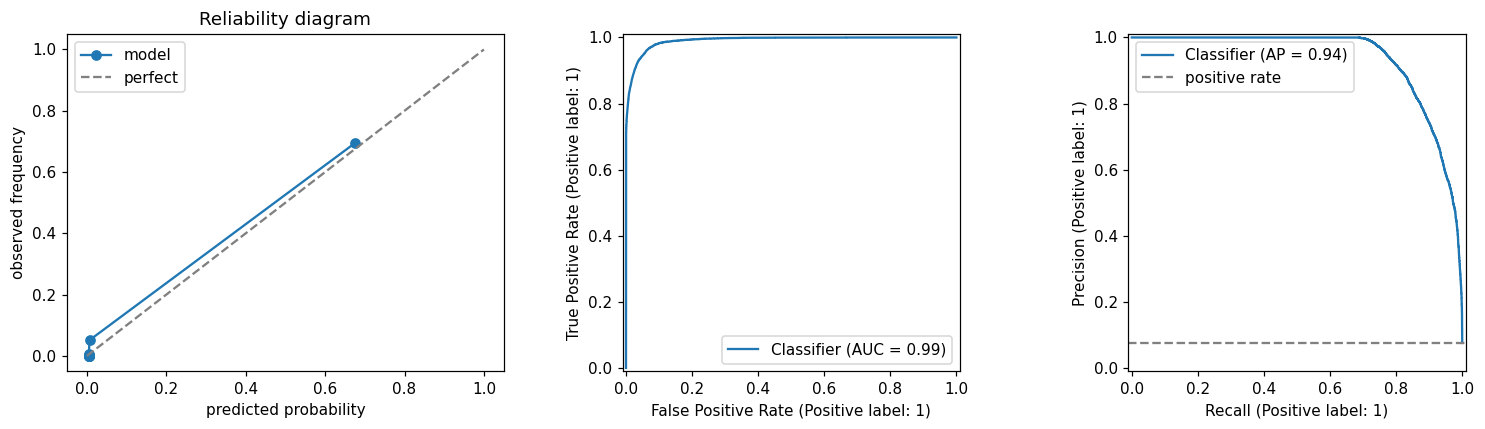

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

frac_pos, mean_pred = calibration_curve(y_test, test_prob, n_bins=10, strategy="quantile")
axes[0].plot(mean_pred, frac_pos, marker="o", label="model")
axes[0].plot([0, 1], [0, 1], "--", color="grey", label="perfect")
axes[0].set(title="Reliability diagram", xlabel="predicted probability", ylabel="observed frequency")
axes[0].legend()

RocCurveDisplay.from_predictions(y_test, test_prob, ax=axes[1])
PrecisionRecallDisplay.from_predictions(y_test, test_prob, ax=axes[2])
axes[2].axhline(y_test.mean(), ls="--", color="grey", label="positive rate")
axes[2].legend()

fig_dir = PROJECT_ROOT / "notebooks" / "figures"
fig_dir.mkdir(exist_ok=True)
plt.tight_layout()
plt.savefig(fig_dir / "cascade_evaluation.png", bbox_inches="tight")
plt.show()

In [10]:
imp = pd.Series(lgbm.feature_importances_, index=FEATURE_COLS).sort_values(ascending=False)
print("top 10 feature importances (split counts):")
print(imp.head(10).to_string())

top 10 feature importances (split counts):
target_pm25_t           1298
target_wind_speed_t      974
target_pm25_zscore_t     960
target_humidity_t        922
target_temp_t            856
hour_cos                 408
month_sin                339
pressure_gradient_t      328
temp_gradient_t          281
source_humidity_t        268


## 8. Save the artifact (production contract)

Keys consumed by `scripts/airshed_pipeline.py`: `classifier`, `imputer`,
`feature_cols`, `optimal_decision_threshold`. The rest is provenance.

In [11]:
imputer = SimpleImputer(strategy="median").fit(X_train)

def _round_metrics(row):
    return {k: (round(v, 4) if isinstance(v, float) else int(v)) for k, v in row.items()}

artifact = {
    "classifier": calibrated,
    "raw_classifier": lgbm,
    "imputer": imputer,
    "feature_cols": FEATURE_COLS,
    "optimal_decision_threshold": best_thr,
    "severe_threshold_ugm3": SEVERE_UGM3,
    "source_anomaly_z_threshold": SOURCE_Z,
    "label_window_tolerance_steps": LABEL_TOL,
    "training_metadata": {
        "version": "3.0.0-clean",
        "created_at": pd.Timestamp.now(tz="Asia/Kolkata").isoformat(),
        "n_rows": {"train": int(len(X_train)), "val": int(len(X_val)), "test": int(len(X_test))},
        "n_edges": len(edges),
        "scale_pos_weight": round(spw, 3),
        "feature_design": "production-parity subset (24 features computable at inference)",
    },
    "verification_metrics": _round_metrics(metrics_df.iloc[0]),
}
joblib.dump(artifact, ARTIFACT_PATH)
print(f"saved -> {ARTIFACT_PATH}")

METRICS_PATH.write_text(json.dumps({
    "threshold": best_thr,
    "scale_pos_weight": spw,
    "test_metrics": _round_metrics(metrics_df.iloc[0]),
    "baseline_metrics": _round_metrics(metrics_df.iloc[1]),
}, indent=2))
print(f"saved -> {METRICS_PATH}")

saved -> C:\Users\ANISH\OneDrive\Desktop\SEM 5\ML\cp\data\models\cascade_predictor.pkl
saved -> C:\Users\ANISH\OneDrive\Desktop\SEM 5\ML\cp\notebooks\metrics.json


## 9. Deploy / rollback

- The artifact path is already wired: `scripts/airshed_pipeline.py` loads
  `data/models/cascade_predictor.pkl`. Re-running the pipeline (locally or via
  the GitHub Actions cron) picks the new model up automatically — the
  `model_version` field changes because the file hash changes.
- **Rollback**: `git checkout <commit> -- data/models/cascade_predictor.pkl`
  and re-run the pipeline.
- Retrain whenever the causal graph is rebuilt, the parquet gains new history,
  or the drift dashboard flags sustained PSI >= 0.2.